# Cumulative Incidence (Competing Risks)

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Plots the probability that a specific event has happened by time t when other events can prevent it, for example relapse when patients can also die without relapsing. The Aalen–Johansen estimator splits cumulative risk correctly between the competing causes.

## When to use

- Show time-to-event outcomes where a competing event removes patients from risk (death before relapse, transplant before death)
- Report the actual absolute risk of a specific event for prognosis or counselling
- Compare cause-specific risks between groups (pair with Gray's test or Fine–Gray regression)

## Avoid when

- There is only one possible event type and censoring is independent (Kaplan–Meier is fine)
- The question is about biological effect rather than absolute risk (cause-specific hazards may suit better)

## Alternatives

- Kaplan–Meier curve (no competing risks)
- Stacked cumulative incidence (to show the total of all causes)

## Design tips

- 1 − Kaplan–Meier overestimates risk because it treats competing events as censored, as if those patients could still have the event later. Show it as a contrast only when teaching this point.
- The cause-specific curves plus the event-free curve add up to 1 at every time point
- Label the curves directly and give the n at risk or the cohort size in the title

## Example

Simulated cohort of 400 patients after surgery, followed for up to 10 years for cancer relapse (event of interest) and death without relapse (competing event).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(8)
n = 400
t_relapse = rng.weibull(1.2, n) * 22          # years
t_death = rng.weibull(1.6, n) * 14
t_censor = rng.uniform(4, 10, n)
time = np.minimum.reduce([t_relapse, t_death, t_censor]).round(2)
cause = np.select([time == t_relapse.round(2), time == t_death.round(2)], [1, 2], default=0)
df = pd.DataFrame({"years": time, "cause": cause})   # 0 = censored, 1 = relapse, 2 = death
df["cause"].map({0: "censored", 1: "relapse", 2: "death w/o relapse"}).value_counts()

cause
censored             222
death w/o relapse     97
relapse               81
Name: count, dtype: int64

### Plot

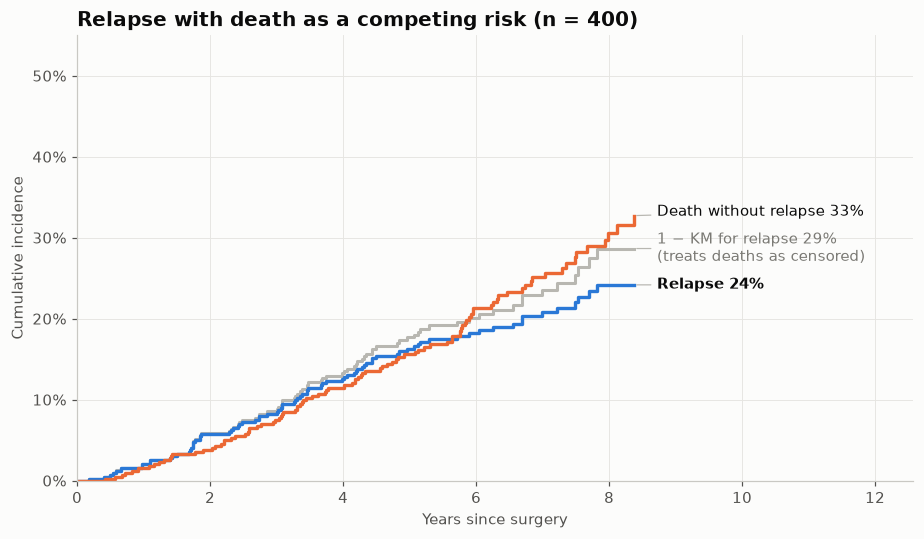

In [3]:
def aalen_johansen(t, c, causes=(1, 2)):
    """Cumulative incidence per cause plus 1-KM for cause 1 (treating others as censored)."""
    times = np.unique(t[c > 0])
    surv, km1 = 1.0, 1.0
    cif = {k: [0.0] for k in causes}
    naive = [0.0]
    for u in times:
        at_risk = (t >= u).sum()
        d = {k: ((t == u) & (c == k)).sum() for k in causes}
        for k in causes:
            cif[k].append(cif[k][-1] + surv * d[k] / at_risk)
        surv *= 1 - sum(d.values()) / at_risk
        km1 *= 1 - d[causes[0]] / at_risk
        naive.append(1 - km1)
    return np.r_[0, times], {k: np.array(v) for k, v in cif.items()}, np.array(naive)

t_grid, cif, naive = aalen_johansen(df["years"].values, df["cause"].values)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.step(t_grid, naive, where="post", color=GRAY, linewidth=2)
ax.step(t_grid, cif[1], where="post", color=PALETTE[0], linewidth=2.2)
ax.step(t_grid, cif[2], where="post", color=PALETTE[1], linewidth=2.2)
end = t_grid[-1]
labels = [  # (curve end value, text, style)
    (naive[-1], f"1 − KM for relapse {naive[-1]:.0%}\n(treats deaths as censored)", dict(color="#7a7974")),
    (cif[1][-1], f"Relapse {cif[1][-1]:.0%}", dict(color="#0b0b0b", fontweight="bold")),
    (cif[2][-1], f"Death without relapse {cif[2][-1]:.0%}", dict(color="#0b0b0b")),
]
labels.sort(key=lambda l: l[0])
ys = [l[0] for l in labels]
for i in range(1, len(ys)):                      # push labels apart so they never overlap
    ys[i] = max(ys[i], ys[i - 1] + 0.045)
for (yv, text, kw), yl in zip(labels, ys):
    ax.annotate(text, xy=(end, yv), xytext=(end + 0.35, yl), va="center", fontsize=9.5,
                arrowprops=dict(arrowstyle="-", color="#b8b7b1", linewidth=0.8), **kw)
ax.set_xlim(0, end + 4.2)
ax.set_ylim(0, max(naive.max(), 0.5) * 1.1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Years since surgery")
ax.set_ylabel("Cumulative incidence")
ax.set_title(f"Relapse with death as a competing risk (n = {len(df)})")
fig.tight_layout()
plt.show()

## How to read it

The blue curve is the true absolute risk of relapse, which ends near a quarter. The gray curve (1 − KM, treating deaths as censored) sits visibly higher and overstates that risk. The orange curve shows how many patients died before they could relapse.

---
Standalone script: [`cumulative_incidence.py`](cumulative_incidence.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)